# Paso 6 · Evaluación final y umbral por costo

Se usa el modelo elegido por PR-AUC de validación en el paso 5, junto con su preprocesador del paso 3. El score genera una alerta de revisión cuando alcanza el umbral. Los umbrales se fijan en validación antes de puntuar prueba.

La simulación suma el monto original de cada fraude omitido y un costo fijo por cada alerta falsa. Se tratan los montos originales como USD para el ejercicio. El caso principal usa 5 USD por alerta falsa y la sensibilidad usa 2 y 10 USD. Se supone que detectar un fraude evita la pérdida completa y que el costo adicional de las alertas verdaderas es cero.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, average_precision_score, confusion_matrix

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data import load_raw, time_split, xy
from src.evaluate import best_threshold, expected_cost, summarize

model_path = project_root / "models/fraud_model.joblib"
if not model_path.is_file():
    raise FileNotFoundError("Ejecuta notebooks/03_models.ipynb completo para generar el modelo.")
artifact = joblib.load(model_path)
if "validation_scores" not in artifact:
    raise ValueError("Vuelve a ejecutar el paso 5 para guardar los puntajes de validación de todos los modelos.")

SEED = 42
FP_COST = 5.0
REVIEW_COSTS = (2.0, FP_COST, 10.0)
_, val, test = time_split(load_raw(project_root / "data/raw/creditcard.csv"))
X_va_raw, y_va = xy(val)
amt_va = val["Amount"].to_numpy()
pre = artifact["preprocessor"]
feature_columns = artifact["feature_columns"]
model_name, model = artifact["name"], artifact["model"]

def risk_scores(estimator, features):
    if model_name == "isolation_forest":
        return -estimator.score_samples(features)
    return estimator.predict_proba(features)[:, 1]

X_va = pre.transform(X_va_raw)[feature_columns]
s_va = risk_scores(model, X_va)
comparison_scores = artifact["validation_scores"]
pd.testing.assert_index_equal(comparison_scores.index, val.index)
np.testing.assert_array_equal(s_va, comparison_scores[model_name].to_numpy())
validation_ap = average_precision_score(y_va, s_va)
np.testing.assert_allclose(validation_ap, artifact["validation_metrics"]["pr_auc"])
print(f"Modelo del paso 5: {model_name} · PR-AUC de validación: {validation_ap:.6f}")
print(f"Validación: {len(val):,} transacciones · {y_va.sum()} fraudes")

Modelo del paso 5: xgboost_tuned · PR-AUC de validación: 0.864248
Validación: 42,558 transacciones · 55 fraudes


## Umbral y curvas de validación

Se evalúa cada score distinto como posible corte, junto con la opción de no alertar. Los scores iguales activan la misma decisión. Si dos cortes tienen el mismo costo, se elige el que genera menos alertas. La precisión promedio (AP) se reporta como PR-AUC para mantener la misma definición que en los pasos 4 y 5.

In [2]:
operating_points = {
    cost: best_threshold(y_va, s_va, amt_va, fp_cost=cost)
    for cost in REVIEW_COSTS
}
thr, cost_va, cutoffs, costs = operating_points[FP_COST]
np.testing.assert_allclose(cost_va, expected_cost(y_va, s_va, amt_va, thr, FP_COST))
no_alerts_va = expected_cost(y_va, s_va, amt_va, np.inf, FP_COST)

validation_operating_points = pd.DataFrame([
    {"Costo por alerta falsa (USD)": fp_cost, "Umbral": cutoff, "Costo de validación (USD)": cost}
    for fp_cost, (cutoff, cost, _, _) in operating_points.items()
])
validation_operating_points.round(6)

,Costo por alerta falsa (USD),Umbral,Costo de validación (USD)
0,2.0,0.574391,182.3
1,5.0,0.574391,206.3
2,10.0,0.574391,246.3


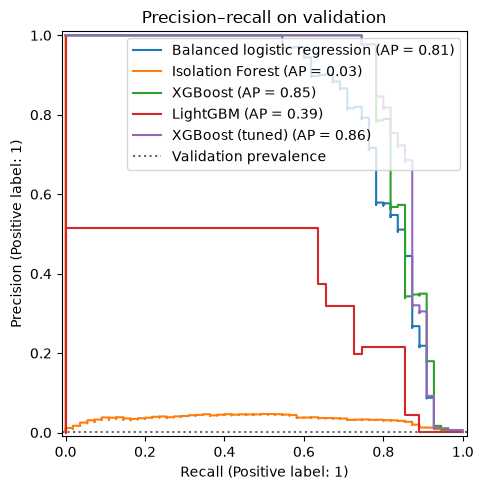

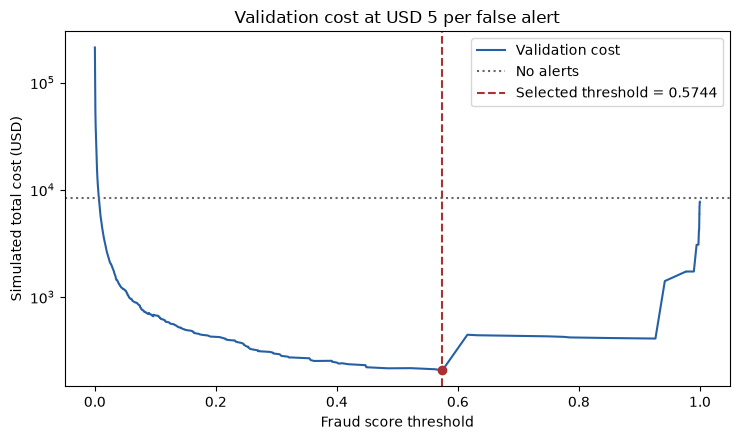

In [3]:
figure_dir = project_root / "reports/figures"
figure_dir.mkdir(parents=True, exist_ok=True)
model_labels = {
    "logreg_balanced": "Balanced logistic regression",
    "isolation_forest": "Isolation Forest",
    "xgboost": "XGBoost",
    "xgboost_tuned": "XGBoost (tuned)",
    "lightgbm": "LightGBM",
}

fig, ax = plt.subplots(figsize=(7.5, 5))
for name in comparison_scores.columns:
    PrecisionRecallDisplay.from_predictions(
        y_va, comparison_scores[name], name=model_labels[name], ax=ax,
    )
ax.axhline(y_va.mean(), color="0.4", linestyle=":", label="Validation prevalence")
ax.set_title("Precision–recall on validation")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(figure_dir / "05_pr_curves.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(cutoffs[:0:-1], costs[:0:-1], color="#2660a4", label="Validation cost")
ax.axhline(no_alerts_va, color="0.4", linestyle=":", label="No alerts")
if np.isfinite(thr):
    ax.axvline(thr, color="#a83232", linestyle="--", label=f"Selected threshold = {thr:.4f}")
    ax.scatter([thr], [cost_va], color="#a83232", zorder=3)
ax.set(
    xlabel="Fraud score threshold",
    ylabel="Simulated total cost (USD)",
    title="Validation cost at USD 5 per false alert",
    yscale="symlog",
)
ax.legend()
fig.tight_layout()
fig.savefig(figure_dir / "06_cost_vs_threshold.png", dpi=150)
plt.show()

## Evaluación en prueba

Se generan los scores de prueba una sola vez. Para el escenario principal y la sensibilidad, se aplican los umbrales ya fijados en validación. La referencia sin alertas pierde la suma de los montos de todos los fraudes de prueba.

Prueba: 42,561 transacciones · 52 fraudes
PR-AUC: 0.765433 · ROC-AUC: 0.980369
Umbral fijado en validación: 0.574390531
Alertas: 53 · TP=39, FP=14, FN=13, TN=42495
Precisión: 73.58% · recall: 75.00%
Fraude omitido: 2,372.40 USD · falsas alertas: 70.00 USD
Costo en prueba: 2,442.40 USD · sin alertas: 6,168.88 USD
Ahorro simulado: 3,726.48 USD (60.41%)


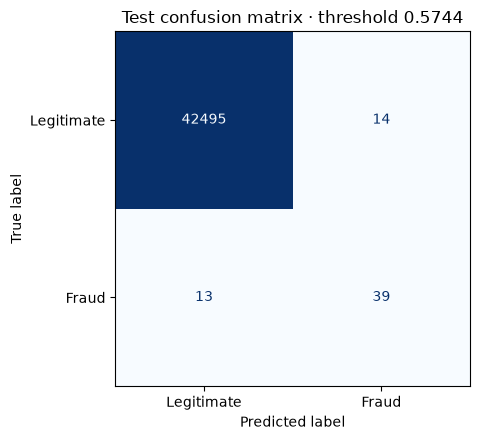

In [4]:
X_te_raw, y_te = xy(test)
amt_te = test["Amount"].to_numpy()
X_te = pre.transform(X_te_raw)[feature_columns]
s_te = risk_scores(model, X_te)
flagged = s_te >= thr
matrix = confusion_matrix(y_te, flagged, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()
cost_nothing = expected_cost(y_te, s_te, amt_te, np.inf, FP_COST)
missed_amount = amt_te[y_te.eq(1).to_numpy() & ~flagged].sum()
cost_te = expected_cost(y_te, s_te, amt_te, thr, FP_COST)
np.testing.assert_allclose(cost_te, missed_amount + fp * FP_COST)
savings = cost_nothing - cost_te
test_metrics = summarize(y_te, s_te, model_name)

print(f"Prueba: {len(y_te):,} transacciones · {int(y_te.sum())} fraudes")
print(f"PR-AUC: {test_metrics['pr_auc']:.6f} · ROC-AUC: {test_metrics['roc_auc']:.6f}")
print(f"Umbral fijado en validación: {thr:.9f}")
print(f"Alertas: {tp + fp} · TP={tp}, FP={fp}, FN={fn}, TN={tn}")
print(f"Precisión: {tp / (tp + fp):.2%} · recall: {tp / (tp + fn):.2%}" if tp + fp else "Sin alertas · recall: 0.00%")
print(f"Fraude omitido: {missed_amount:,.2f} USD · falsas alertas: {fp * FP_COST:,.2f} USD")
print(f"Costo en prueba: {cost_te:,.2f} USD · sin alertas: {cost_nothing:,.2f} USD")
print(f"Ahorro simulado: {savings:,.2f} USD ({savings / cost_nothing:.2%})")

fig, ax = plt.subplots(figsize=(6, 4.5))
ConfusionMatrixDisplay(matrix, display_labels=["Legitimate", "Fraud"]).plot(
    ax=ax, values_format="d", colorbar=False, cmap="Blues",
)
ax.set_title(f"Test confusion matrix · threshold {thr:.4f}")
fig.tight_layout()
fig.savefig(figure_dir / "07_confusion_test.png", dpi=150)
plt.show()

## Incertidumbre del PR-AUC

Se remuestrean transacciones de prueba con reemplazo, manteniendo fijos los scores del modelo. El intervalo percentil del 95 % resume la variabilidad del PR-AUC para esta muestra bajo el supuesto de observaciones independientes. El remuestreo por transacción no representa cambios temporales ni la incertidumbre del entrenamiento.

In [5]:
rng = np.random.default_rng(SEED)
labels_te = y_te.to_numpy()
boot_ap = []
for _ in range(1000):
    indices = rng.integers(0, len(labels_te), size=len(labels_te))
    labels = labels_te[indices]
    if labels.any():
        boot_ap.append(average_precision_score(labels, s_te[indices]))
lo, hi = np.percentile(boot_ap, [2.5, 97.5])
print(f"PR-AUC en prueba: {test_metrics['pr_auc']:.6f} · IC95 % [{lo:.6f}, {hi:.6f}]")
print(f"Réplicas válidas: {len(boot_ap):,} de 1,000 (semilla {SEED})")

PR-AUC en prueba: 0.765433 · IC95 % [0.653280, 0.865480]
Réplicas válidas: 1,000 de 1,000 (semilla 42)


## Errores del escenario principal

Se contrastan los fraudes detectados y omitidos en prueba. Para seleccionar las variables de esta comparación se mide, en validación, cuánto cae el PR-AUC al permutar cada variable. Las horas se agrupan desde el primer registro del dataset. Los componentes PCA son anónimos y sus valores no permiten identificar comportamientos de negocio.

In [6]:
def score_average_precision(estimator, features, labels):
    return average_precision_score(labels, risk_scores(estimator, features))

importance = permutation_importance(
    model, X_va, y_va, scoring=score_average_precision, n_repeats=3, random_state=SEED,
)
ap_drop = pd.Series(importance.importances_mean, index=feature_columns, name="Caída media de AP en validación")
top_features = ap_drop.nlargest(3).index
frauds = test.loc[test["Class"].eq(1)].copy()
frauds["Detectado"] = flagged[labels_te == 1]
frauds["Hora relativa"] = ((frauds["Time"] // 3600) % 24).astype(int)
missed, detected = frauds.loc[~frauds["Detectado"]], frauds.loc[frauds["Detectado"]]

features_summary = pd.DataFrame({
    ap_drop.name: ap_drop[top_features],
    "Mediana de omitidos": missed[top_features].median(),
    "Mediana de detectados": detected[top_features].median(),
})
display(features_summary.round(4))

if not missed.empty and not detected.empty:
    hours = missed["Hora relativa"].value_counts().sort_index()
    busiest_hour = int(hours.idxmax())
    biggest_shift = (features_summary["Mediana de omitidos"] - features_summary["Mediana de detectados"]).abs().idxmax()
    print(f"1. Se omitieron {len(missed)} de {len(frauds)} fraudes ({len(missed) / len(frauds):.1%}), "
          f"que suman {missed_amount:,.2f} USD ({missed_amount / cost_nothing:.1%} del monto fraudulento).")
    print(f"2. Mediana del monto: {missed['Amount'].median():,.2f} USD en omitidos y "
          f"{detected['Amount'].median():,.2f} USD en detectados. El mayor omitido fue de {missed['Amount'].max():,.2f} USD.")
    print(f"3. Los omitidos se repartieron en {len(hours)} horas relativas. En la hora {busiest_hour:02d} "
          f"hubo {hours.max()} de los {len(missed)} omitidos y {frauds['Hora relativa'].eq(busiest_hour).sum()} fraudes en total.")
    print(f"4. Entre las tres variables de mayor importancia en validación, {biggest_shift} mostró "
          f"la mayor diferencia absoluta de medianas: {missed[biggest_shift].median():.3f} en omitidos y "
          f"{detected[biggest_shift].median():.3f} en detectados.")
else:
    print(f"Fraudes omitidos: {len(missed)} · detectados: {len(detected)}. La comparación de ambos grupos requiere casos en cada uno.")

1. Se omitieron 13 de 52 fraudes (25.0%), que suman 2,372.40 USD (38.5% del monto fraudulento).
2. Mediana del monto: 12.31 USD en omitidos y 4.69 USD en detectados. El mayor omitido fue de 1,096.99 USD.
3. Los omitidos se repartieron en 6 horas relativas. En la hora 19 hubo 4 de los 13 omitidos y 12 fraudes en total.
4. Entre las tres variables de mayor importancia en validación, V14 mostró la mayor diferencia absoluta de medianas: -1.426 en omitidos y -8.397 en detectados.


,Caída media de AP en validación,Mediana de omitidos,Mediana de detectados
V4,0.1079,1.0870,5.1048
V12,0.0380,0.1446,-5.2672
V14,0.0353,-1.4256,-8.3966


## Sensibilidad al costo de revisión

Cada umbral de la tabla minimiza el costo en validación para su tarifa correspondiente. Se aplica luego a los mismos scores de prueba. La tarifa cambia tanto la decisión de alertar como el costo de cada falsa alerta.

In [7]:
sensitivity_rows = []
for fp_cost, (cutoff, validation_cost, _, _) in operating_points.items():
    decisions = s_te >= cutoff
    _, scenario_fp, scenario_fn, scenario_tp = confusion_matrix(y_te, decisions, labels=[0, 1]).ravel()
    test_cost = expected_cost(y_te, s_te, amt_te, cutoff, fp_cost)
    sensitivity_rows.append({
        "Costo por alerta falsa (USD)": fp_cost,
        "Umbral": cutoff,
        "Costo de validación (USD)": validation_cost,
        "TP en prueba": scenario_tp,
        "FP en prueba": scenario_fp,
        "FN en prueba": scenario_fn,
        "Costo de prueba (USD)": test_cost,
        "Ahorro en prueba (%)": 100 * (cost_nothing - test_cost) / cost_nothing,
    })
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.round({"Umbral": 6, "Costo de validación (USD)": 2, "Costo de prueba (USD)": 2, "Ahorro en prueba (%)": 2})

,Costo por alerta falsa (USD),Umbral,Costo de validación (USD),TP en prueba,FP en prueba,FN en prueba,Costo de prueba (USD),Ahorro en prueba (%)
0,2.0,0.574391,182.3,39,14,13,2400.4,61.09
1,5.0,0.574391,206.3,39,14,13,2442.4,60.41
2,10.0,0.574391,246.3,39,14,13,2512.4,59.27


El conjunto de datos cubre aproximadamente dos días y la muestra de prueba contiene pocos fraudes. Los scores sirven para ordenar el riesgo y se emplean como tales en esta evaluación. Los costos representan una simulación con variables anonimizadas. El paso 4 reportó las métricas de prueba de la línea base. Para el ganador del paso 5 y los tres cortes de este notebook, todas las decisiones se tomaron usando validación.